In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset and inspect structure
df = pd.read_csv('Dataset.csv')

print("Dataset Shape:", df.shape)
print("\n--- First 3 Rows ---")
display(df.head(3))

print("\n--- Data Types & Missing Values ---")
data_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
print(data_summary)

Dataset Shape: (129880, 22)

--- First 3 Rows ---


,satisfaction,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,2,...,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,3,...,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,3,...,2,2,3,3,4,4,4,2,0,0.0



--- Data Types & Missing Values ---
                                  Data Type  Missing Values  \
satisfaction                         object               0   
Customer Type                        object               0   
Age                                   int64               0   
Type of Travel                       object               0   
Class                                object               0   
Flight Distance                       int64               0   
Seat comfort                          int64               0   
Departure/Arrival time convenient     int64               0   
Food and drink                        int64               0   
Gate location                         int64               0   
Inflight wifi service                 int64               0   
Inflight entertainment                int64               0   
Online support                        int64               0   
Ease of Online booking                int64               0   
On-board service  

In [3]:
# Data Cleaning (Handling Missing Values & Duplicates)
print(f"Original duplicate rows count: {df.duplicated().sum()}")

# Drop duplicate rows if any exist
df = df.drop_duplicates()

# Checking missing values for 'Arrival Delay in Minutes'
print("\nMissing values before handling:", df['Arrival Delay in Minutes'].isnull().sum())

# Since arrival delay is numerical, we can impute missing values with the median or drop them. 
# Let's use median imputation to preserve data integrity:
median_arrival_delay = df['Arrival Delay in Minutes'].median()
df['Arrival Delay in Minutes'].fillna(median_arrival_delay, inplace=True)

print("Missing values after handling:", df['Arrival Delay in Minutes'].isnull().sum())
print("Cleaned Dataset Shape:", df.shape)

Original duplicate rows count: 0

Missing values before handling: 393
Missing values after handling: 0
Cleaned Dataset Shape: (129880, 22)


--- Target Variable Distribution (satisfaction) ---
satisfaction
satisfied       71087
dissatisfied    58793
Name: count, dtype: int64
satisfaction
satisfied       54.73283
dissatisfied    45.26717
Name: proportion, dtype: float64

--- Numerical Features Summary ---


,Age,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000
mean,39.427957,1981.409055,2.838597,2.990645,2.851994,2.990422,3.249130,3.383477,3.519703,3.472105,3.465075,3.485902,3.695673,3.340807,3.705759,3.352587,14.713713,15.045465
std,15.119360,1027.115606,1.392983,1.527224,1.443729,1.305970,1.318818,1.346059,1.306511,1.305560,1.270836,1.292226,1.156483,1.260582,1.151774,1.298715,38.071126,38.416353
min,7.000000,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,1359.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,1925.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,4.000000,0.000000,0.000000
75%,51.000000,2544.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,85.000000,6951.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


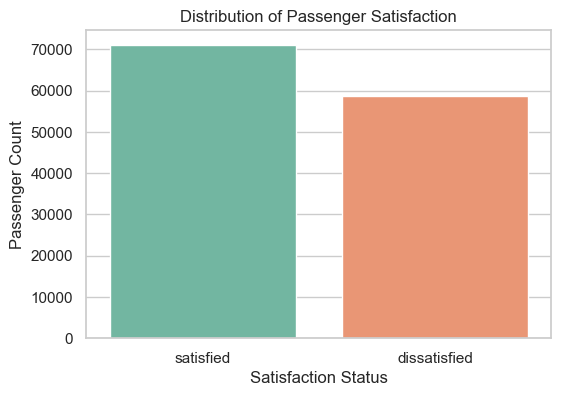

In [4]:
# Univariate Analysis and Summary Statistics
print("--- Target Variable Distribution (satisfaction) ---")
print(df['satisfaction'].value_counts())
print(df['satisfaction'].value_counts(normalize=True) * 100)

# Summary statistics for numerical features
print("\n--- Numerical Features Summary ---")
display(df.describe())

# Visualizing the target variable distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='satisfaction', palette='Set2')
plt.title('Distribution of Passenger Satisfaction')
plt.xlabel('Satisfaction Status')
plt.ylabel('Passenger Count')
plt.show()

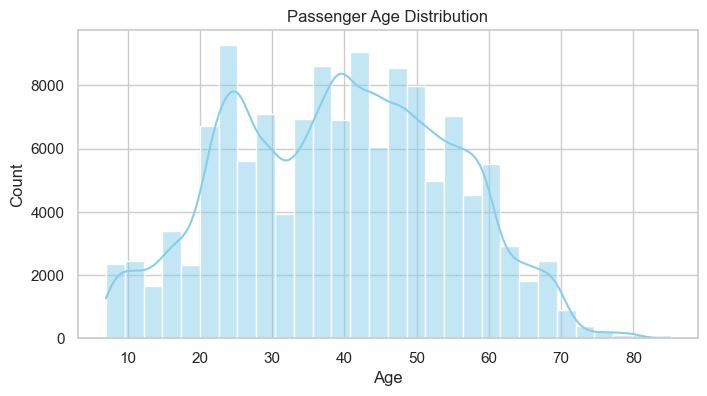

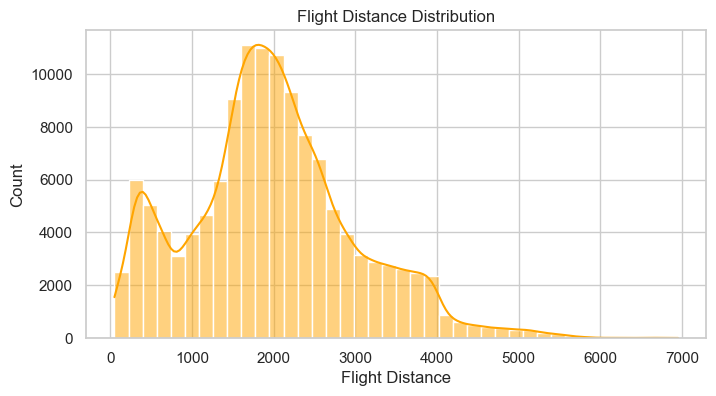

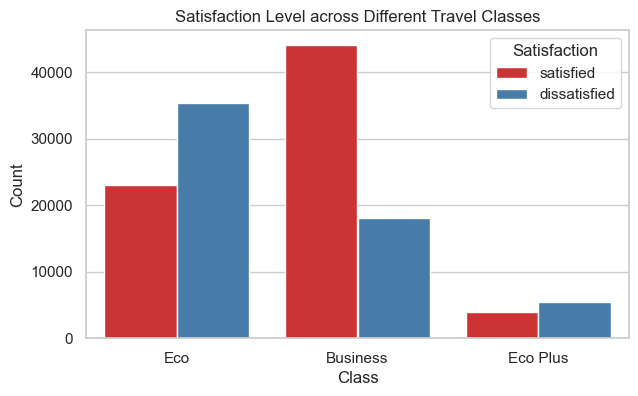

In [5]:
# Exploratory Data Analysis - Visualizing Key Features
# Age Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'], kde=True, bins=30, color='skyblue')
plt.title('Passenger Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

# Flight Distance Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Flight Distance'], kde=True, bins=40, color='orange')
plt.title('Flight Distance Distribution')
plt.xlabel('Flight Distance')
plt.ylabel('Count')
plt.show()

# Satisfaction by Travel Class
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Class', hue='satisfaction', palette='Set1')
plt.title('Satisfaction Level across Different Travel Classes')
plt.xlabel('Class')
plt.ylabel('Count')
plt.legend(title='Satisfaction')
plt.show()

In [6]:
# Save the cleaned dataset
df.to_csv('cleaned_dataset.csv', index=False)
print("Cleaned dataset successfully saved as 'cleaned_dataset.csv'!")

Cleaned dataset successfully saved as 'cleaned_dataset.csv'!
